# 04 · Scoring sémantique, recommandation et explications (P4)

**Projet NLP GenderBook, ECE ING5 Data & IA.** Ce notebook déroule, étape par étape, comment le système passe des réponses du questionnaire à un **top 3 de livres expliqué**. Il sert aussi de base à la section « Scoring & recommandation » du rapport.

Modules utilisés (tous dans `src/`) :

| Module | Rôle |
|---|---|
| `schemas.py` | dataclasses `UserProfile` et `Recommendation` (contrat avec l'app de P5) |
| `profile.py` | `build_profile(answers, engine)` : réponses → profil sémantique |
| `scoring.py` | la formule de score, calculée de façon vectorisée |
| `recommender.py` | `recommend(answers, top_k=3)` : point d'entrée unique de l'app |
| `explain.py` | explications par template, sans LLM |
| `fallback_engine.py` | moteur d'embeddings de secours tant que `embeddings.py` (P3) n'est pas livré |

**Pipeline :**
```
answers.json ─► build_profile ─► (1) filtres durs ─► (2) retrieval top-300 par S_desc
             ─► (3) re-ranking par la formule ─► (4) diversité ─► (5) top 3 + explications
```

**Formule** (détaillée en section 6) :

$$\text{Final}(j) = \frac{\alpha\,\tilde S_{desc}(j) + \beta\,\text{Coverage}(j) + \lambda\,\text{Pop}(j)}{\alpha+\beta+\lambda} \;-\; \mu \max\big(0,\ \cos(q_{avoid}, e_j) - \tau\big)$$

$$\text{Coverage}(j) = \frac{\sum_b W_b\,\tilde S_b(j)}{\sum_b W_b}, \qquad S_b(j) = \frac{1}{|P_b|}\sum_{p\in P_b}\ \max_{l \in L_b(j)\cup\{e_j\}} \cos(p, l)$$

## 1. Mise en place

On se place à la racine du repo pour pouvoir importer `src/`. Le modèle SBERT (`all-MiniLM-L6-v2`) est téléchargé au premier lancement (≈ 90 Mo), puis l'encodage des 12 000 résumés prend quelques minutes sur CPU. Il est ensuite **mis en cache** dans `data/embeddings/` : les lancements suivants sont instantanés.

> Mode hors-ligne (tests uniquement) : `GENDERBOOK_ENCODER=lsa` remplace SBERT par TF-IDF + SVD. Les résultats sont alors moins bons : ne pas l'utiliser pour le rapport.

In [1]:
# Étape 1 : rendre le dossier src/ importable depuis notebooks/
import sys, os, json, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config
from src.data_loader import load_books
from src.recommender import Recommender, load_blocks_safe
from src.profile import build_profile, likert_to_sentence, LIKERT_SENTENCES
from src.scoring import score_books, load_personas, calibrate, book_label_mask, desc_similarity
from src.explain import explain_score_formula
from src.schemas import BLOCKS

pd.set_option("display.max_colwidth", 120)
print("Encodeur :", os.environ.get("GENDERBOOK_ENCODER", "sbert"), "| modèle :", config.EMBEDDING_MODEL)

Encodeur : sbert | modèle : sentence-transformers/all-MiniLM-L6-v2


In [2]:
# Étape 2 : charger le catalogue (enrichi par P2 s'il existe, sinon propre ou échantillon de P1)
books = load_books()
blocks = load_blocks_safe()
print(f"{len(books)} livres | colonnes P2 présentes : {all(c in books for c in ['genres','themes','styles','atmospheres'])}")
print({b: len(v) for b, v in blocks.items()}, "labels par bloc")
books[["title", "main_author", "audience", "genres", "themes", "styles", "atmospheres", "popularity"]].head(3)

12000 livres | colonnes P2 présentes : True
{'Genre': 21, 'Themes': 20, 'Style': 10, 'Atmosphere': 15} labels par bloc


,title,main_author,audience,genres,themes,styles,atmospheres,popularity
0,Harry Potter and the Sorcerer's Stone,J.K. Rowling,Children,"[Fantasy, Humour, Children's]",[Friendship],[Simple & accessible],[Whimsical & magical],0.896000
1,The Hunger Games,Suzanne Collins,Young Adult,"[Young Adult, Historical Fiction]","[Grief & loss, Survival, Coming of age]",[Humorous & witty],[Melancholic],0.857940
2,"Twilight : Twilight, Book 1",Stephenie Meyer,Young Adult,"[Literary Fiction, Fantasy, Young Adult]",[Adventure & exploration],"[Plot-driven & twisty, Fast-paced page-turner]",[Dark & unsettling],0.705516


In [3]:
# Étape 3 : construire le moteur (catalogue + embeddings + phrases de labels + calibration)
# Le premier appel encode les 12 000 résumés (cache disque ensuite).
t0 = time.time()
reco = Recommender(books=books, blocks=blocks)
print(f"Moteur prêt en {time.time() - t0:.1f} s | moteur : {type(reco.engine).__name__} "
      f"| matrice des livres : {reco.book_emb.shape}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Moteur prêt en 18.4 s | moteur : EmbeddingEngine | matrice des livres : (12000, 384)


## 2. Un utilisateur exemple

On utilise un persona de `data/reference/personas_p4.json` (format exact de `answers.json`, contrat §4.3). Il combine les **5 types de questions** exigés : texte libre, cases à cocher, choix multiple, Likert et questions guidées.

In [4]:
personas = load_personas()
answers = personas["dark_academia"]
print(json.dumps(answers, indent=2, ensure_ascii=False))

{
  "free_text": {
    "ideal_book": "I enjoy psychological novels exploring identity and moral dilemmas, with complex characters who hide dark secrets.",
    "loved_book": "I loved The Secret History because of the dark academic atmosphere and the group of students drawn into a crime.",
    "atmosphere": "Something melancholic, rainy, set in an old university",
    "avoid": "No romance-centered plots, no gore"
  },
  "genres": [
    "Literary Fiction",
    "Thriller & Suspense"
  ],
  "themes": [
    "Identity & self-discovery",
    "Morality & guilt",
    "Friendship"
  ],
  "period": "Contemporary",
  "audience": "Adult",
  "formats": [],
  "favorite_author": "Donna Tartt",
  "guided": {
    "focus": "Characters",
    "standalone_only": false,
    "exclude_favorite_author": true
  },
  "likert": {
    "complexity": 4,
    "pace": 2,
    "darkness": 4,
    "popularity": 3,
    "w_genre": 4,
    "w_themes": 5,
    "w_style": 3,
    "w_atmosphere": 4
  }
}


## 3. Étape 1 : le profil sémantique (`build_profile`)

### 3.1 Les Likert deviennent des phrases

C'est le point clé pour respecter la consigne « *not purely numerical* ». Une note de 1 à 5 n'a pas de sens pour un modèle de langue : on la **convertit en phrase**, qui est encodée puis comparée aux livres comme n'importe quel texte. Le niveau 3 (neutre) ne produit pas de phrase : il signifie « pas de préférence » et ne doit pas diluer le bloc.

In [5]:
# Tableau de conversion Likert -> phrase (utilisé pour les blocs Style et Atmosphere)
rows = []
for key, levels in LIKERT_SENTENCES.items():
    for v in range(1, 6):
        rows.append({"likert": key, "valeur": v, "phrase encodée": likert_to_sentence(key, v) or "(neutre : aucune phrase)"})
pd.DataFrame(rows)

,likert,valeur,phrase encodée
0,complexity,1,"a simple, easy and accessible story with clear, straightforward writing"
1,complexity,2,"an easy-to-read, light narrative that is not too demanding"
2,complexity,3,(neutre : aucune phrase)
3,complexity,4,a rich and layered narrative with some depth and complexity
4,complexity,5,"a complex, dense, literary and demanding narrative with sophisticated prose"
5,pace,1,"a slow, contemplative and quiet story that takes its time"
6,pace,2,"a gently paced, reflective story"
7,pace,3,(neutre : aucune phrase)
8,pace,4,a well-paced story with momentum and suspense
9,pace,5,"a fast-paced, gripping page-turner that is hard to put down"


### 3.2 Les phrases de préférence par bloc $P_b(u)$

Pour chaque bloc, on rassemble les phrases qui décrivent ce que veut l'utilisateur :

- **Genre** : la phrase descriptive (`blocks.json`) de chaque genre coché ;
- **Thèmes** : les phrases des thèmes cochés + la réponse libre « un livre que vous avez adoré et pourquoi » ;
- **Style** : les Likert complexité et rythme convertis en phrases + la question guidée *character / plot-driven* ;
- **Atmosphère** : l'époque choisie (label de P2) + le Likert tonalité en phrase + la réponse libre sur l'ambiance.

On encode la **phrase** d'un label, pas le mot seul : « boy wizard school » se rapproche ainsi de *Fantasy* sans que le mot apparaisse.

In [6]:
profile = build_profile(answers, reco.engine, reco.books, reco.blocks)
for b in BLOCKS:
    print(f"\n{b}  (poids W = {profile.weights[b]:.0f})")
    for p in profile.block_phrases[b]:
        print("   •", p)
print("\nλ (bonus popularité) =", profile.lambda_pop)
print("Texte à éviter, négations retirées :", repr(profile.query_texts["avoid"]))
print("Auteur préféré retrouvé dans le catalogue :", profile.favorite_author)


Genre  (poids W = 4)
   • Literary fiction, a character-focused novel with artistic prose, psychological depth and insight into society
   • Gripping thriller and suspense novel with danger, conspiracies, spies, chases and high-stakes tension

Themes  (poids W = 5)
   • A story about self-discovery, identity and finding out who you really are
   • A story about moral dilemmas, right and wrong, guilt, conscience and consequences of choices
   • A story about friendship, loyalty, companionship and the people who stand by us
   • I loved The Secret History because of the dark academic atmosphere and the group of students drawn into a crime.

Style  (poids W = 3)
   • a rich and layered narrative with some depth and complexity
   • a gently paced, reflective story
   • a character-driven story with deep psychological portraits and inner lives

Atmosphere  (poids W = 4)
   • Set in the modern world today, with contemporary life, smartphones and current social issues
   • a serious, somber 

**Pourquoi retirer les négations du texte « à éviter » ?** SBERT encode mal la négation : « *No romance* » est presque aussi proche des romances que « *romance* ». Plutôt que de lutter contre ce biais, on l'exploite : on garde le **sujet** à éviter (« romance-centered plots, gore ») et on pénalise les livres qui en sont proches.

### 3.3 Résumé du profil et affinités (radar de l'app)

`block_affinities[b][label]` = similarité maximale entre les préférences de l'utilisateur et la phrase de chaque label. P5 s'en sert pour le radar « profil lecteur ».

In [7]:
print(profile.summary, "\n")
for b in BLOCKS:
    top = sorted(profile.block_affinities[b].items(), key=lambda kv: -kv[1])[:5]
    print(f"{b:<11}", " | ".join(f"{l} {s:.2f}" for l, s in top))

You are looking for Literary Fiction, Thriller & Suspense books exploring identity & self-discovery, morality & guilt, friendship. Your ideal style looks like: character-driven. Preferred atmosphere: contemporary and melancholic. What matters most to you: themes. Favourite author: Donna Tartt. Audience: Adult. 

Genre       Thriller & Suspense 1.00 | Literary Fiction 1.00 | Young Adult 0.55 | Historical Fiction 0.55 | Mystery & Detective 0.54
Themes      Friendship 0.89 | Morality & guilt 0.88 | Identity & self-discovery 0.84 | Redemption 0.60 | Family relationships 0.57
Style       Character-driven 0.95 | Dense literary prose 0.75 | Slow and contemplative 0.74 | Dark & gritty voice 0.58 | Fast-paced page-turner 0.56
Atmosphere  Contemporary 1.00 | Melancholic 0.64 | Dark & unsettling 0.62 | Future 0.55 | Romantic 0.47


### 3.4 Requête globale : concaténation ou moyenne ?

`q_global` combine les 3 réponses libres. Deux options :

- **concaténation** : un seul texte, le modèle voit tout le contexte, mais une longue réponse écrase les autres et MiniLM tronque au-delà de 256 tokens ;
- **moyenne** des embeddings de chaque réponse : chaque réponse pèse autant et aucune n'est tronquée.

On compare les deux sur les personas : recouvrement des 10 premiers livres retrouvés et cosinus entre les deux vecteurs.

In [8]:
rows = []
for name, a in personas.items():
    p_mean = build_profile(a, reco.engine, reco.books, reco.blocks, how="mean")
    p_cat = build_profile(a, reco.engine, reco.books, reco.blocks, how="concat")
    top_m = set(np.argsort(-(reco.book_emb @ p_mean.query_vecs["global"]))[:10])
    top_c = set(np.argsort(-(reco.book_emb @ p_cat.query_vecs["global"]))[:10])
    rows.append({"persona": name,
                 "cos(q_mean, q_concat)": float(p_mean.query_vecs["global"] @ p_cat.query_vecs["global"]),
                 "top-10 communs": len(top_m & top_c)})
pd.DataFrame(rows).round(3)

,persona,"cos(q_mean, q_concat)",top-10 communs
0,dark_academia,0.951,5
1,young_fantasy,0.927,7
2,nordic_noir,0.938,6
3,philosophy_essay,0.893,8
4,historical_romance,0.945,6
5,dystopian_scifi,0.890,7
6,cozy_feelgood,0.950,8
7,true_life_memoir,0.861,4


**Lecture.** Les deux vecteurs sont proches (cosinus entre 0,86 et 0,95), mais pas identiques : selon le persona, seuls 4 à 8 des 10 premiers livres sont communs. Le choix a donc un effet réel. L'écart est le plus grand pour les personas dont une réponse est beaucoup plus longue que les autres (*true_life_memoir* : 4/10). C'est exactement le cas où la concaténation laisse la réponse la plus longue dominer. Nous gardons la **moyenne** (`config.QUERY_COMBINATION = "mean"`) : chaque question ouverte pèse autant, et aucune n'est tronquée à 256 tokens. Si l'auteur préféré est trouvé dans le catalogue, on mélange : $q_{global} = 0.7\,q_{texte} + 0.3\,\bar e_{auteur}$ (centroïde de ses livres), puis on renormalise.

## 4. Étape 2 : filtres durs et retrieval

Les **filtres durs** (`data_loader.apply_constraints` de P1) retirent les livres hors public, hors format ou de l'auteur exclu. Ensuite, le **retrieval** garde les 300 livres dont le résumé est le plus proche de $q_{global}$ (un produit matrice-vecteur sur 12 000 livres, quelques millisecondes). Le re-ranking, plus coûteux, ne porte que sur ces candidats.

Si aucun livre ne passe les filtres, on relâche dans l'ordre : formats, période de publication, fiction, public. Les auteurs exclus ne sont jamais relâchés.

Livres qui passent les filtres : 9337 / 12000  | filtres relâchés : []


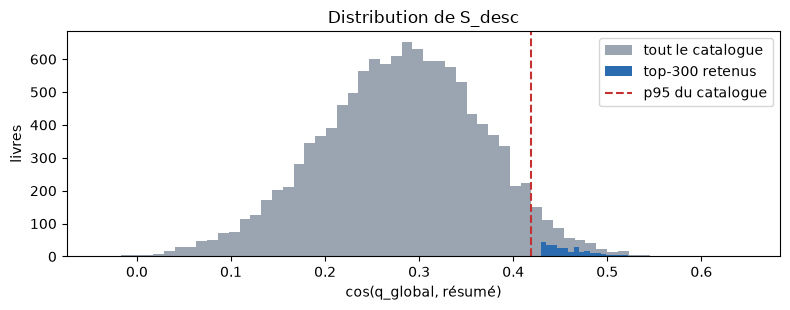

Part des candidats au-dessus du p95 du catalogue : 100%


In [9]:
mask = reco.filter_mask(profile, min_books=1)
print(f"Livres qui passent les filtres : {mask.sum()} / {len(mask)}  | filtres relâchés : {profile.constraints['relaxed']}")

sims_all = desc_similarity(profile.query_vecs["global"], reco.book_emb)
allowed = np.flatnonzero(mask)
cand = allowed[np.argsort(-sims_all[allowed])[:config.RETRIEVAL_TOP_K]]

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(sims_all, bins=60, color="#9aa5b1", label="tout le catalogue")
ax.hist(sims_all[cand], bins=30, color="#2b6cb0", label=f"top-{config.RETRIEVAL_TOP_K} retenus")
ax.axvline(np.percentile(sims_all, 95), color="#c53030", ls="--", label="p95 du catalogue")
ax.set_xlabel("cos(q_global, résumé)"); ax.set_ylabel("livres"); ax.legend(); ax.set_title("Distribution de S_desc")
plt.tight_layout(); plt.show()
print(f"Part des candidats au-dessus du p95 du catalogue : {(sims_all[cand] > np.percentile(sims_all, 95)).mean():.0%}")

## 5. Étape 3 : la calibration

Les cosinus SBERT sont **compressés** (souvent entre 0,1 et 0,7) : 0,45 peut être un excellent score. Pour les rendre lisibles et comparables entre composantes, on les ramène sur [0, 1] :

$$\tilde s = \text{clip}\left(\frac{s - p_5}{p_{95} - p_5},\ 0,\ 1\right)$$

**Choix important.** Le graphique ci-dessus montre que les 300 candidats sont *tous* au-dessus du p95 du catalogue (le retrieval garde le top 2,5 %). Calibrer sur le catalogue entier donnerait donc $\tilde S_{desc} = 1$ à tous les candidats et ce terme ne départagerait plus rien. Nous calculons donc $p_5$ et $p_{95}$ **sur les candidats retrouvés pour 8 personas de référence**. La calibration est ensuite **fixe** (enregistrée dans `data/embeddings/calibration_p4.json`) : un score de 0,8 a le même sens pour tous les utilisateurs.

In [10]:
pd.DataFrame(reco.calibration, index=["p5", "p95"]).T.round(3)

,p5,p95
S_desc,0.373,0.547
Genre,0.296,1.000
Themes,0.347,0.675
Style,0.368,0.870
Atmosphere,0.247,0.627


## 6. Étape 4 : le calcul à la main sur 3 livres

Comme l'exemple « Step 1 à 5 » du sujet, on détaille chaque terme pour 3 livres du top. On recalcule la couverture et le score final **à la main** et on vérifie qu'on retrouve la sortie de `score_books`.

Rappel des constantes (`src/config.py`) : $\alpha = 0.5$ (résumé), $\beta = 0.4$ (couverture), $\lambda \in [0; 0.2]$ (popularité, réglé par le Likert), $\mu = 0.5$ et $\tau = 0.3$ (pénalité « à éviter »).

In [11]:
table = reco.score_table(profile)
top3 = table.head(3)
cols = ["S_desc_raw", "S_desc"] + [c for b in BLOCKS for c in (f"{b}_raw", b)] + ["coverage", "popularity", "avoid_sim", "penalty", "final"]
show = top3[cols].copy()
show.insert(0, "title", reco.books.loc[top3.index, "title"].str[:40])
show.round(3)

,title,S_desc_raw,S_desc,Genre_raw,Genre,Themes_raw,Themes,Style_raw,Style,Atmosphere_raw,Atmosphere,coverage,popularity,avoid_sim,penalty,final
861,The Secret Keeper,0.571,1.0,1.000,1.000,0.486,0.422,0.487,0.237,0.313,0.175,0.470,0.619,0.210,0.0,0.750
6233,The Keep,0.564,1.0,0.772,0.677,0.561,0.651,0.536,0.336,0.343,0.252,0.499,0.416,0.295,0.0,0.741
10758,My Secret : A PostSecret Book,0.602,1.0,0.735,0.623,0.561,0.652,0.465,0.193,0.279,0.086,0.417,0.479,0.275,0.0,0.715


In [12]:
# Recalcul manuel du score du 1er livre, terme par terme
row = top3.iloc[0]
W = profile.weights; lam = profile.lambda_pop
a, b_, mu, tau = config.ALPHA_DESC, config.BETA_COVERAGE, config.MU_AVOID, config.TAU_AVOID

print("Calibration de S_desc :", f"({row.S_desc_raw:.3f} - {reco.calibration['S_desc'][0]:.3f}) / "
      f"({reco.calibration['S_desc'][1]:.3f} - {reco.calibration['S_desc'][0]:.3f}) -> {row.S_desc:.3f}")
cov = sum(W[b] * row[b] for b in BLOCKS) / sum(W.values())
print("Coverage = (" + " + ".join(f"{W[b]:.0f}×{row[b]:.3f}" for b in BLOCKS) + f") / {sum(W.values()):.0f} = {cov:.3f}")
pen = mu * max(0.0, row.avoid_sim - tau)
final = (a * row.S_desc + b_ * cov + lam * row.popularity) / (a + b_ + lam) - pen
print(f"Final = ({a}×{row.S_desc:.3f} + {b_}×{cov:.3f} + {lam}×{row.popularity:.3f}) / {a + b_ + lam:.2f} - {pen:.3f} = {final:.3f}")
assert abs(cov - row.coverage) < 1e-5 and abs(min(max(final, 0), 1) - row.final) < 1e-5
print("✔ identique à score_books")

Calibration de S_desc : (0.571 - 0.373) / (0.547 - 0.373) -> 1.000
Coverage = (4×1.000 + 5×0.422 + 3×0.237 + 4×0.175) / 16 = 0.470
Final = (0.5×1.000 + 0.4×0.470 + 0.1×0.619) / 1.00 - 0.000 = 0.750
✔ identique à score_books


**Justification de chaque terme :**

- **$\tilde S_{desc}$ (α = 0,5)** : la similarité entre ce que l'utilisateur écrit et le résumé du livre. C'est le signal sémantique le plus riche (texte libre contre texte libre), d'où le poids le plus élevé.
- **Coverage (β = 0,4)** : la moyenne pondérée des 4 blocs, exigée par le sujet. Elle vérifie que le livre couvre *chaque* dimension demandée (genre, thèmes, style, atmosphère) et pas seulement le sujet général. Les poids $W_b$ viennent directement des Likert d'importance : l'utilisateur décide de ce qui compte.
- **Règle « max puis moyenne » dans $S_b$** : pour chaque préférence, on garde le label du livre qui y répond le mieux (max), puis on fait la moyenne sur les préférences. Un livre doit donc répondre à *toutes* les préférences du bloc pour avoir un bon score. La description $e_j$ est ajoutée aux candidats du max : si P2 n'a pas attribué un label, le résumé peut encore répondre.
- **λ·Pop (0 à 0,2)** : un petit bonus aux livres connus et bien notés, réglé par le Likert « pépites ↔ best-sellers ». Il reste petit pour ne jamais dominer la sémantique.
- **Division par α + β + λ** : garantit Final ∈ [0, 1] quel que soit λ, pour que les seuils *Excellent ≥ 0,75 / Good ≥ 0,55 / Partial* aient le même sens pour tous les utilisateurs.
- **Pénalité μ·max(0, cos − τ)** : ne s'applique qu'au-delà de τ = 0,3 (en dessous, la ressemblance avec le sujet à éviter est du bruit), et μ = 0,5 la rend nettement visible.

## 7. Étape 5 : le top 3 final, avec ses explications

`recommend()` enchaîne tout, applique la **diversité** (au plus un livre par auteur) puis construit les objets `Recommendation`. L'explication est générée par **template** à partir des résultats réels : similarité, phrase du résumé la plus proche, labels communs, critère le plus fort et le plus faible.

In [13]:
profile, recs = reco.recommend(answers, top_k=3)
for r in recs:
    print(f"#{r.rank}  {r.title} | {r.authors}  →  {r.final_score:.0%} ({r.match_label})")
    print("   Explanation :", r.explanation)
    print("   " + explain_score_formula(r, profile).replace("\n", "\n   "))
    print()

#1  The Secret Keeper | Kate Morton  →  75% (Good)
   Explanation : This book is a good match for your preferences. Its synopsis is semantically close to your description (similarity 0.57), especially: «Shifting between the 1930s, the 1960s and the present, The Secret Keeper is a spellbinding story of mysteries and secrets, murder and enduring love.». It shares the themes you care about: Family relationships (0.57), Coming of age (0.46). Genre match: Thriller & Suspense (1.00), Literary Fiction (1.00). Its style (Fast-paced page-turner (0.56), Plot-driven & twisty (0.51)) fits the kind of writing you asked for. What weighs most in its score: how close its synopsis is to your description. It is a weaker match on the atmosphere (17%). Overall preference coverage: 47%. It is also a popular, well-rated book.
   S_desc (calibrated) = 1.00  (raw cosine 0.57)
   S_Genre = 1.00  (raw 1.00, weight W=4)
   S_Themes = 0.42  (raw 0.49, weight W=5)
   S_Style = 0.24  (raw 0.49, weight W=3)
   S_Atm

In [14]:
# Décomposition du score (ce que P5 affiche en barres empilées) : la somme des contributions = score final
pd.DataFrame({r.title[:35]: r.contributions for r in recs}).T.round(3)

,Description,Genre,Themes,Style,Atmosphere,Popularity,Avoid penalty
The Secret Keeper,0.5,0.100,0.053,0.018,0.018,0.062,-0.0
The Keep,0.5,0.068,0.081,0.025,0.025,0.042,-0.0
My Secret : A PostSecret Book,0.5,0.062,0.082,0.014,0.009,0.048,-0.0



**Lecture du top 3 (persona *dark academia*).** *The Secret Keeper* (Kate Morton) et *The Keep* (Jennifer Egan) sont cohérents : de la fiction littéraire à secrets, crimes et culpabilité. Le 3e livre, *My Secret: A PostSecret Book*, est en revanche **hors sujet** : c'est un recueil non-fictionnel de cartes postales anonymes. Deux limites l'expliquent :

1. **Le mot « secrets » de la description** (« *characters who hide dark secrets* ») tire fortement la similarité : ce livre a même le cosinus brut le plus élevé des trois (0,60). SBERT capte le *sujet* commun, pas la *nature* du livre (roman ou témoignage).
2. **Un label de P2 erroné** : le livre porte le genre *Thriller & Suspense*, ce qui lui donne un bon score Genre alors qu'il ne s'agit pas d'un thriller.

Cette erreur est gardée volontairement comme **limite documentée**. Une piste simple d'amélioration : quand l'utilisateur ne coche que des genres de fiction, filtrer automatiquement la non-fiction (`is_fiction`, colonne de P1).

On remarque aussi que les 3 livres ont $\tilde S_{desc} = 1$ : parmi les meilleurs candidats, la similarité globale dépasse le p95 de calibration. Le terme résumé ne départage donc plus le haut du classement, et ce sont la **couverture** et la **popularité** qui ordonnent le top 3.


## 8. Trois personas contrastés : le système est-il cohérent ?

On vérifie que des demandes très différentes donnent des recommandations très différentes et pertinentes : fantasy jeunesse, polar nordique sombre, essai philosophique. On mesure aussi une **précision de genre** simple : la part des livres du top 3 qui portent au moins un des genres cochés.

In [15]:
def genre_precision(recs, wanted):
    g = reco.books.set_index("book_id").loc[[r.book_id for r in recs], "genres"]
    return float(np.mean([bool(set(x) & set(wanted)) for x in g])) if len(recs) else 0.0

rows = []
for name in ["young_fantasy", "nordic_noir", "philosophy_essay"]:
    p, rs = reco.recommend(personas[name], top_k=3)
    for r in rs:
        rows.append({"persona": name, "rang": r.rank, "titre": r.title[:45], "auteur": r.authors[:25],
                     "score": r.final_score, "label": r.match_label,
                     "genres du livre": ", ".join(reco.books.set_index("book_id").at[r.book_id, "genres"])})
    print(f"{name:<17} précision de genre@3 = {genre_precision(rs, personas[name]['genres']):.2f}")
pd.DataFrame(rows)

young_fantasy     précision de genre@3 = 1.00
nordic_noir       précision de genre@3 = 1.00
philosophy_essay  précision de genre@3 = 1.00


,persona,rang,titre,auteur,score,label,genres du livre
0,young_fantasy,1,"The Lion, the Witch and the Wardrobe",C. S. Lewis,0.8957,Excellent,"Fantasy, Literary Fiction, Young Adult"
1,young_fantasy,2,The Neverending Story,Michael Ende,0.8311,Excellent,"Fantasy, Classics, Young Adult"
2,young_fantasy,3,The Farthest Shore,Ursula K Le Guin,0.8030,Excellent,"Fantasy, Young Adult, Science Fiction"
3,nordic_noir,1,An Incomplete Revenge,Jacqueline Winspear,0.8948,Excellent,"Mystery & Detective, Thriller & Suspense"
4,nordic_noir,2,The Shining Girls,Lauren Beukes,0.8811,Excellent,"Thriller & Suspense, Mystery & Detective, Literary Fiction"
5,nordic_noir,3,The Girl Who Kicked the Hornets' Nest : The t,Stieg Larsson,0.8781,Excellent,"Mystery & Detective, Thriller & Suspense, Cooking & Lifestyle"
6,philosophy_essay,1,THE Power of Now,Eckhart Tolle,0.9518,Excellent,Philosophy & Religion
7,philosophy_essay,2,Status Anxiety,Alain de Botton,0.9284,Excellent,"Self-help & Psychology, Philosophy & Religion"
8,philosophy_essay,3,Awareness,Anthony de Mello,0.9088,Excellent,"Philosophy & Religion, Self-help & Psychology"


## 9. Sensibilité : les réglages de l'utilisateur ont-ils l'effet attendu ?

Trois vérifications rapides :

1. **Poids des thèmes** : on passe $W_{Themes}$ de 1 à 5 ; le score Thèmes moyen du top 10 doit monter.
2. **Popularité** : on passe le Likert de 1 (pépites) à 5 (best-sellers) ; la popularité moyenne du top 10 doit monter.
3. **Texte à éviter** : on ajoute « no romance » ; les livres proches de la romance doivent être pénalisés.

In [16]:
import copy

def top10_mean(a, col):
    p = build_profile(a, reco.engine, reco.books, reco.blocks)
    t = reco.score_table(p).head(10)
    return float(t[col].mean())

base = copy.deepcopy(personas["dark_academia"]); base["free_text"]["avoid"] = ""
rows = []
for w in (1, 5):
    a = copy.deepcopy(base); a["likert"]["w_themes"] = w
    rows.append({"réglage": f"w_themes = {w}", "mesure": "S̃_Themes moyen (top 10)", "valeur": top10_mean(a, "Themes")})
for pop in (1, 5):
    a = copy.deepcopy(base); a["likert"]["popularity"] = pop
    rows.append({"réglage": f"popularity = {pop}", "mesure": "popularité moyenne (top 10)", "valeur": top10_mean(a, "popularity")})
for avoid in ("", "No romance, no love story"):
    a = copy.deepcopy(base); a["free_text"]["avoid"] = avoid
    p = build_profile(a, reco.engine, reco.books, reco.blocks)
    t = reco.score_table(p).head(10)
    is_rom = reco.books.loc[t.index, "genres"].map(lambda g: "Romance" in g)
    rows.append({"réglage": f"avoid = {avoid!r}", "mesure": "livres Romance dans le top 10", "valeur": int(is_rom.sum())})
pd.DataFrame(rows).round(3)

,réglage,mesure,valeur
0,w_themes = 1,S̃_Themes moyen (top 10),0.368
1,w_themes = 5,S̃_Themes moyen (top 10),0.432
2,popularity = 1,popularité moyenne (top 10),0.500
3,popularity = 5,popularité moyenne (top 10),0.500
4,avoid = '',livres Romance dans le top 10,1.000
5,"avoid = 'No romance, no love story'",livres Romance dans le top 10,1.000



**Lecture.** Une seule des trois vérifications donne l'effet attendu :

- **Poids des thèmes** : passer $W_{Themes}$ de 1 à 5 fait monter le score Thèmes moyen du top 10 de 0,37 à 0,43. Le Likert d'importance agit bien sur le classement.
- **Popularité** : le Likert de 1 à 5 ne change pas la popularité moyenne du top 10 (0,50 dans les deux cas). Avec $\lambda \le 0{,}2$, le bonus reste trop faible pour réordonner les 10 premiers livres de ce persona. C'est voulu (la popularité ne doit pas dominer la sémantique), mais l'effet est quasi invisible. P6 pourra tester $\lambda_{max} = 0{,}4$ dans l'ablation.
- **Texte à éviter** : ajouter « No romance » ne retire pas le livre de romance du top 10. Avec MiniLM, la similarité entre « romance, love story » et les résumés reste le plus souvent sous le seuil $\tau = 0{,}3$ : la pénalité ne se déclenche presque jamais. P6 pourra tester $\tau = 0{,}2$.

Ces deux derniers points sont des **limites mesurées**, reportées dans le bilan (section 12) et le rapport.


## 10. Mini-ablation de la formule

P6 fera l'ablation complète. Ici, une première vérification sur les 8 personas : on compare la formule complète à des variantes amputées d'un terme, avec la précision de genre@3 et le recouvrement du top 3 avec la formule complète.

In [17]:
variants = {
    "formule complète": {},
    "S_desc seul": {"alpha": 1.0, "beta": 0.0},
    "Coverage seule": {"alpha": 0.0, "beta": 1.0},
    "sans calibration": {"use_calibration": False},
    "sans pénalité avoid": {"mu": 0.0},
}
ref_top = {}
rows = []
for vname, kw in variants.items():
    precs, overlaps = [], []
    for name, a in personas.items():
        p, rs = reco.recommend(a, top_k=3, **kw)
        ids = [r.book_id for r in rs]
        if vname == "formule complète":
            ref_top[name] = set(ids)
        precs.append(genre_precision(rs, a["genres"]))
        overlaps.append(len(set(ids) & ref_top[name]) / 3)
    rows.append({"variante": vname, "précision de genre@3": np.mean(precs), "top 3 communs avec la formule complète": np.mean(overlaps)})
pd.DataFrame(rows).round(2)

,variante,précision de genre@3,top 3 communs avec la formule complète
0,formule complète,0.92,1.00
1,S_desc seul,0.75,0.38
2,Coverage seule,1.00,0.21
3,sans calibration,0.96,0.71
4,sans pénalité avoid,0.92,1.00


**Lecture.**

- **S_desc seul** fait chuter la précision de genre (0,75 contre 0,92) : sans les blocs, le texte libre seul ramène des livres proches par le sujet mais pas par le genre (comme *PostSecret* plus haut).
- **Coverage seule** atteint 1,00 en précision de genre, mais ne garde que 21 % du top 3 de la formule complète. Ce chiffre est flatteur par construction : la précision de genre mesure les labels de P2, que la couverture optimise directement. En revanche, cette variante ignore la nuance du texte libre (l'ambiance, le livre adoré).
- **Sans calibration** : 71 % du top 3 est conservé, et la précision monte légèrement (0,96). Sans calibration, le bloc Genre (cosinus de 1 quand le label est exact) pèse davantage.
- **Sans pénalité avoid** : rien ne change (100 % du top 3 conservé), ce qui confirme que la pénalité ne se déclenche presque jamais avec $\tau = 0{,}3$ (voir section 9).

**Conclusion** : combiner le texte libre et la couverture (α = 0,5, β = 0,4) est un compromis entre fidélité à la description et respect des genres cochés. Les chiffres portent sur 8 personas seulement : P6 confirmera avec son ablation complète.

## 11. Performance

In [18]:
t0 = time.time()
for a in personas.values():
    reco.recommend(a, top_k=3)
dt = (time.time() - t0) / len(personas)
print(f"Temps moyen d'une recommandation complète (profil + scoring + explications) : {dt * 1000:.0f} ms")

Temps moyen d'une recommandation complète (profil + scoring + explications) : 328 ms


## 12. Bilan et limites

**Ce que fait la partie P4 :**
- transforme *toutes* les réponses (y compris Likert et choix guidés) en phrases encodées par SBERT : l'analyse reste sémantique de bout en bout ;
- calcule un score d'affinité par bloc et un **score de couverture** $\sum W_b S_b / \sum W_b$, conformément au sujet ;
- recommande un top 3 diversifié, chaque livre avec son score, son libellé, ses critères principaux, la phrase du résumé la plus proche et une explication par template ;
- calcule tout en numpy (aucune boucle sur les livres) : une recommandation complète prend environ 0,3 s sur CPU, dont l'essentiel sert à encoder les réponses et à chercher la phrase la plus proche.

**Résultats mesurés (MiniLM, 12 000 livres) :** précision de genre@3 de 1,00 sur les 3 personas contrastés et de 0,92 sur les 8 personas ; le poids des thèmes agit bien sur le classement.

**Limites :**
- **Proximité de sujet ≠ pertinence** : un mot fort de la demande peut faire remonter un livre hors sujet. Exemple mesuré : *My Secret: A PostSecret Book* (non-fiction) dans le top 3 du persona *dark academia*, à cause du mot « secrets ». Piste : filtrer la non-fiction quand l'utilisateur ne coche que des genres de fiction ;
- **Dépendance aux labels de P2** (F1 thèmes ≈ 0,40 sur le jeu de test) : *PostSecret* porte à tort le genre *Thriller & Suspense*. La description sert de filet de sécurité, mais une erreur de label se propage au score ;
- **Saturation de $\tilde S_{desc}$ en haut du classement** : les meilleurs candidats dépassent le p95 de calibration, donc le terme résumé ne départage plus le top 3 ;
- **Popularité et pénalité « à éviter » peu actives** : avec $\lambda \le 0{,}2$ et $\tau = 0{,}3$, elles ne changent pas le top 10 du persona testé ; à régler par l'ablation de P6 ;
- **Négation** : SBERT gère mal la négation ; nous retirons les mots négatifs du texte « à éviter », mais une phrase nuancée (« pas trop de romance, un peu ça va ») reste mal comprise ;
- **Calibration** : elle dépend des 8 personas de référence ; plus de personas (P6) la rendraient plus robuste ;
- **Série** : pas d'information de série dans le dataset, donc la préférence « standalone only » est enregistrée mais pas filtrée.